In [ ]:
from google.colab import drive; drive.mount('/content/drive')
import pandas as pd, glob



Mounted at /content/drive


In [ ]:
base = '/content/drive/MyDrive/Features'   # folder that holds S2, S3, chest_all...
for f in sorted(glob.glob(f'{base}/S2/chest/*.parquet')) + sorted(glob.glob(f'{base}/chest_all/*.parquet')):
    df = pd.read_parquet(f)
    print(f"\n== {f.split('/')[-1]}  shape={df.shape}")
    print(df.dtypes.value_counts().to_dict())
    print(df.head(3))
    for c in [c for c in df.columns if 'label' in c.lower() or 'subject' in c.lower()]:
        print(c, df[c].value_counts().to_dict())


== S2_chest_acc.parquet  shape=(114, 28)
{dtype('float64'): 25, dtype('int64'): 2, dtype('O'): 1}
  subject  window_idx  start_time  end_time  label  chest_acc_x_mean  \
0      S2           0       270.0     330.0      1          0.870751   
1      S2           1       300.0     360.0      1          0.788427   
2      S2           2       330.0     390.0      1          0.658962   

   chest_acc_x_std  chest_acc_x_min  chest_acc_x_max  chest_acc_x_range  ...  \
0         0.018655           0.7674           0.9562             0.1888  ...   
1         0.121517           0.5390           1.1454             0.6064  ...   
2         0.092938           0.5390           1.1454             0.6064  ...   

   chest_acc_z_std  chest_acc_z_min  chest_acc_z_max  chest_acc_z_range  \
0         0.047558           -0.458          -0.1742             0.2838   
1         0.235889           -0.870           0.6110             1.4810   
2         0.203902           -0.870           0.6110             1

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  WESAD CNN-LSTM · Predict stress on EVERY window (all labels)
#  Paste into ONE Colab cell (CPU runtime is enough) and run.
#
#  For each subject it runs:
#    A) FOLD model  fold_<S>.weights.h5  → the subject was NOT in training
#                                          (honest, unseen-subject result)
#    B) FINAL model final_model.keras    → trained on baseline+stress of ALL
#                                          subjects (amusement/meditation are
#                                          still unseen windows for it)
#
#  Preprocessing is copied 1:1 from your training notebook:
#    merge bundles → feature order → median-impute → StandardScaler → to_3d
#  Fold scaler = refit on the other 14 subjects' baseline+stress windows,
#  exactly like run_loso() did.
# ═══════════════════════════════════════════════════════════════════════════

# ── CONFIG ─────────────────────────────────────────────────────────────────
BASE_PATH  = '/content/drive/MyDrive/Features'
MODEL_DIR  = '/content/drive/MyDrive/dl_models/cnn_lstm'
OUTPUT_DIR = '/content/drive/MyDrive/dl_results/all_label_predictions'

# Which trained experiment(s) to evaluate. Use ['chest_all'] or list several,
# e.g. list(EXPERIMENTS) for all 12 (still only a few minutes on CPU).
RUN_EXPERIMENTS = 'all'

THRESHOLD = 0.5
MOUNT_DRIVE = True
# ───────────────────────────────────────────────────────────────────────────

EXPERIMENTS = {
    'chest_acc':         {'chest': ['acc']},
    'chest_eda':         {'chest': ['eda']},
    'chest_emg':         {'chest': ['emg']},
    'chest_heart':       {'chest': ['heart']},
    'chest_statistical': {'chest': ['statistical']},
    'wrist_acc':         {'wrist': ['acc']},
    'wrist_eda':         {'wrist': ['eda']},
    'wrist_heart':       {'wrist': ['heart']},
    'wrist_statistical': {'wrist': ['statistical']},
    'chest_all':  {'chest': ['acc', 'eda', 'emg', 'heart', 'statistical']},
    'wrist_all':  {'wrist': ['acc', 'eda', 'heart', 'statistical']},
    'multimodal': {'chest': ['acc', 'eda', 'emg', 'heart', 'statistical'],
                   'wrist': ['acc', 'eda', 'heart', 'statistical']},
}

LABEL_NAMES = {0: 'transient', 1: 'baseline', 2: 'stress', 3: 'amusement',
               4: 'meditation', 5: 'label_5', 6: 'label_6', 7: 'label_7'}

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

import json, gc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, balanced_accuracy_score)
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

MERGE_KEYS       = ['subject', 'window_idx', 'start_time', 'end_time', 'label']
NON_FEATURE_COLS = set(MERGE_KEYS)
SENSOR_PREFIXES  = ['acc', 'eda', 'emg', 'heart', 'temp', 'bvp', 'resp', 'scl', 'scr']
OUT = Path(OUTPUT_DIR); OUT.mkdir(parents=True, exist_ok=True)


# ── Same functions as the training notebook ────────────────────────────────
def load_all_labels(config):
    """load_dataset() from training, but WITHOUT the baseline/stress filter."""
    all_dfs = []
    for modality, bundles in config.items():
        dfs = [pd.read_parquet(Path(BASE_PATH) / modality / f'all_{modality}_{b}.parquet')
               for b in bundles]
        merged = dfs[0]
        for df in dfs[1:]:
            merged = merged.merge(df, on=MERGE_KEYS)
        all_dfs.append(merged)
    final = all_dfs[0]
    for df in all_dfs[1:]:
        final = final.merge(df, on=MERGE_KEYS)
    return final.reset_index(drop=True)          # raw labels 1..7 kept


def get_feature_names(df):
    return [c for c in df.columns if c not in NON_FEATURE_COLS]


def group_by_sensor(feature_names):
    groups = {}
    for col in feature_names:
        matched = next((p for p in SENSOR_PREFIXES if col.lower().startswith(p)), None)
        groups.setdefault(matched if matched else 'other', []).append(col)
    return groups


def to_3d(X_2d, feature_names):
    groups  = group_by_sensor(feature_names)
    g_names = list(groups.keys())
    T       = max(len(v) for v in groups.values())
    c_idx   = {n: i for i, n in enumerate(feature_names)}
    X_3d    = np.zeros((X_2d.shape[0], len(g_names), T), dtype=np.float32)
    for gi, gn in enumerate(g_names):
        for fi, col in enumerate(groups[gn]):
            X_3d[:, gi, fi] = X_2d[:, c_idx[col]]
    return X_3d


def build_model(input_shape):
    inp = keras.Input(shape=input_shape)
    x = layers.Conv1D(64, 3, padding='same', activation='relu')(inp)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.2)(x)
    x = layers.Conv1D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.2)(x)
    x = layers.LSTM(64, return_sequences=False)(x); x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x);     x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)


def impute_scale(X_fit_raw, X_apply_raw, medians=None, scaler=None):
    """Fit (or reuse) medians + scaler on X_fit_raw, apply to X_apply_raw."""
    X_fit, X_app = X_fit_raw.copy(), X_apply_raw.copy()
    if medians is None:
        medians = np.nanmedian(X_fit, axis=0)
    for arr in (X_fit, X_app):
        m = np.isnan(arr)
        if m.any():
            arr[m] = np.take(medians, np.where(m)[1])
    if scaler is None:
        scaler = StandardScaler().fit(X_fit)
    X_sc = np.nan_to_num(scaler.transform(X_app), nan=0.0, posinf=0.0, neginf=0.0)
    return X_sc


def predict(model, X3d):
    return model(X3d, training=False).numpy().ravel()


# ── Metrics ────────────────────────────────────────────────────────────────
def binary_metrics(y_true, probs, thr=THRESHOLD):
    if len(y_true) == 0:
        return {}
    pred = (probs >= thr).astype(int)
    try:
        auc = roc_auc_score(y_true, probs)
    except ValueError:
        auc = np.nan
    tn = int(((pred == 0) & (y_true == 0)).sum()); fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum()); tp = int(((pred == 1) & (y_true == 1)).sum())
    return dict(n=len(y_true), accuracy=accuracy_score(y_true, pred),
                balanced_acc=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0),
                specificity=tn / (tn + fp) if (tn + fp) else np.nan,
                f1=f1_score(y_true, pred, zero_division=0),
                roc_auc=auc, tp=tp, fp=fp, fn=fn, tn=tn)


def summarise(pred_df, tag):
    """Per subject: (1) original task  baseline vs stress,
                    (2) strict task    stress vs EVERYTHING else,
                    (3) % of windows flagged as stress for each real label."""
    rows = []
    for sub, g in pred_df.groupby('subject'):
        bs = g[g['label'].isin([1, 2])]
        orig   = binary_metrics((bs['label'] == 2).astype(int).values, bs['prob'].values)
        strict = binary_metrics((g['label'] == 2).astype(int).values, g['prob'].values)
        row = {'subject': sub}
        row.update({f'orig_{k}': v for k, v in orig.items()})
        row.update({f'strict_{k}': v for k, v in strict.items()})
        rows.append(row)
    metrics = pd.DataFrame(rows)
    metrics['subj_num'] = metrics['subject'].str[1:].astype(int)
    metrics = metrics.sort_values('subj_num').drop(columns='subj_num')

    flag = (pred_df.assign(flagged=pred_df['pred'])
            .pivot_table(index='subject', columns='label_name', values='flagged', aggfunc='mean'))
    cnt  = pred_df.pivot_table(index='subject', columns='label_name', values='pred', aggfunc='size')
    order = [LABEL_NAMES[k] for k in sorted(LABEL_NAMES) if LABEL_NAMES[k] in flag.columns]
    key = lambda idx: idx.str[1:].astype(int)
    flag = (flag[order] * 100).round(1).sort_index(key=key)
    cnt  = cnt[order].sort_index(key=key)

    # pooled over all subjects
    pooled = (pred_df.groupby('label_name')['pred']
              .agg(windows='size', flagged_stress='sum', pct_flagged='mean'))
    pooled['pct_flagged'] = (pooled['pct_flagged'] * 100).round(1)
    pooled = pooled.reindex([o for o in order if o in pooled.index])

    print(f"\n{'─'*70}\n {tag}\n{'─'*70}")
    print("\n% of windows the model called STRESS, by REAL label (rows = subjects):")
    print(flag.fillna('-').to_string())
    print("\nPooled over all subjects:")
    print(pooled.to_string())
    cols = ['subject', 'orig_accuracy', 'orig_f1', 'orig_roc_auc',
            'strict_accuracy', 'strict_balanced_acc', 'strict_precision',
            'strict_recall', 'strict_f1']
    print("\nPer-subject metrics  (orig = baseline vs stress | strict = stress vs all other labels):")
    print(metrics[cols].round(3).to_string(index=False))
    print("\nMean across subjects:")
    print(metrics[cols[1:]].mean().round(3).to_string())
    return metrics, flag, cnt, pooled


# ── Main loop ──────────────────────────────────────────────────────────────
for exp in RUN_EXPERIMENTS:
    config  = EXPERIMENTS[exp]
    exp_dir = Path(MODEL_DIR) / exp
    print(f"\n{'═'*70}\n  EXPERIMENT: {exp}\n{'═'*70}")

    df   = load_all_labels(config)
    feat = get_feature_names(df)
    X_all_raw = df[feat].values.astype(np.float32)
    is_bs     = df['label'].isin([1, 2]).values          # training-eligible rows
    df['label_name'] = df['label'].map(LABEL_NAMES).fillna(df['label'].astype(str))
    subjects = sorted(df['subject'].unique(), key=lambda s: int(s[1:]))
    print(f"windows={len(df)} | features={len(feat)} | subjects={len(subjects)}")
    print("label counts:", df['label_name'].value_counts().to_dict())

    input_shape = to_3d(X_all_raw[:1], feat).shape[1:]
    print("model input shape:", input_shape)

    # ── A) fold models (unseen subject) ────────────────────────────────────
    fold_rows = []
    tf.keras.backend.clear_session()
    model = build_model(input_shape)
    for sub in subjects:
        wpath = exp_dir / f'fold_{sub}.weights.h5'
        if not wpath.exists():
            print(f"  [skip] {wpath.name} not found"); continue
        model.load_weights(str(wpath))
        train_mask = is_bs & (df['subject'] != sub).values  # same as run_loso
        test_mask  = (df['subject'] == sub).values           # ALL labels
        X_te = impute_scale(X_all_raw[train_mask], X_all_raw[test_mask])
        probs = predict(model, to_3d(X_te, feat))
        part = df.loc[test_mask, ['subject', 'window_idx', 'start_time', 'end_time',
                                  'label', 'label_name']].copy()
        part['prob'] = probs
        part['pred'] = (probs >= THRESHOLD).astype(int)
        fold_rows.append(part)
        print(f"  fold {sub:>4}: {test_mask.sum()} windows predicted")
    del model; gc.collect()

    if fold_rows:
        fold_pred = pd.concat(fold_rows, ignore_index=True)
        fold_pred.insert(0, 'model', 'fold')
        m, f, c, p = summarise(fold_pred, f"{exp} · FOLD models (subject unseen)")
        fold_pred.to_csv(OUT / f'{exp}_fold_predictions.csv', index=False)
        m.to_csv(OUT / f'{exp}_fold_metrics.csv', index=False)
        f.to_csv(OUT / f'{exp}_fold_pct_flagged_by_label.csv')
        c.to_csv(OUT / f'{exp}_window_counts_by_label.csv')

    # ── B) final model (trained on all subjects' baseline+stress) ─────────
    fpath = exp_dir / 'final_model.keras'
    if fpath.exists():
        tf.keras.backend.clear_session()
        final = keras.models.load_model(str(fpath), compile=False)
        meta_p, sc_p, md_p = exp_dir / 'meta.json', exp_dir / 'scaler.joblib', exp_dir / 'medians.npy'
        feat_final = json.load(open(meta_p))['feature_names'] if meta_p.exists() else feat
        X_final_raw = df[feat_final].values.astype(np.float32)
        if sc_p.exists() and md_p.exists():
            import joblib
            scaler, medians = joblib.load(sc_p), np.load(md_p)
            X_sc = impute_scale(X_final_raw[is_bs], X_final_raw, medians=medians, scaler=scaler)
            print("\nfinal model: using saved scaler.joblib + medians.npy")
        else:
            X_sc = impute_scale(X_final_raw[is_bs], X_final_raw)
            print("\nfinal model: scaler refit on all baseline+stress windows (no saved scaler found)")
        probs = predict(final, to_3d(X_sc, feat_final))
        final_pred = df[['subject', 'window_idx', 'start_time', 'end_time',
                         'label', 'label_name']].copy()
        final_pred['prob'] = probs
        final_pred['pred'] = (probs >= THRESHOLD).astype(int)
        final_pred.insert(0, 'model', 'final')
        m, f, c, p = summarise(final_pred,
                               f"{exp} · FINAL model (baseline/stress windows were in training!)")
        final_pred.to_csv(OUT / f'{exp}_final_predictions.csv', index=False)
        m.to_csv(OUT / f'{exp}_final_metrics.csv', index=False)
        f.to_csv(OUT / f'{exp}_final_pct_flagged_by_label.csv')
        del final; gc.collect()
    else:
        print(f"  [skip] {fpath} not found")

print(f"\n✅ Done. CSVs saved in {OUT}")


# ── Optional plots (run after the loop) ────────────────────────────────────
import matplotlib.pyplot as plt

def plot_heatmap(exp='chest_all', which='fold'):
    """Subjects × real label, colour = % of windows called stress."""
    tbl = pd.read_csv(OUT / f'{exp}_{which}_pct_flagged_by_label.csv', index_col=0)
    fig, ax = plt.subplots(figsize=(1.3 * tbl.shape[1] + 2, 0.4 * tbl.shape[0] + 1.5))
    im = ax.imshow(tbl.values, cmap='Reds', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(tbl.shape[1])); ax.set_xticklabels(tbl.columns, rotation=30, ha='right')
    ax.set_yticks(range(tbl.shape[0])); ax.set_yticklabels(tbl.index)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.0f}', ha='center', va='center',
                        color='white' if v > 60 else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, label='% windows predicted "stress"')
    ax.set_title(f'{exp} · {which} model: where does it see stress?')
    plt.tight_layout(); plt.savefig(OUT / f'{exp}_{which}_heatmap.png', dpi=150); plt.show()


def plot_timeline(subject='S2', exp='chest_all', which='fold'):
    """Stress probability over the session, coloured by the real label."""
    d = pd.read_csv(OUT / f'{exp}_{which}_predictions.csv')
    d = d[d['subject'] == subject].sort_values('start_time')
    colours = {'baseline': '#4C78A8', 'stress': '#E45756', 'amusement': '#F2B701',
               'meditation': '#54A24B', 'label_6': '#999999', 'label_7': '#666666'}
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(d['start_time'] / 60, d['prob'], color='#bbbbbb', lw=1, zorder=1)
    for name, g in d.groupby('label_name'):
        ax.scatter(g['start_time'] / 60, g['prob'], s=18, label=name,
                   color=colours.get(name, '#000000'), zorder=2)
    ax.axhline(THRESHOLD, ls='--', color='black', lw=0.8)
    ax.set_ylim(-0.05, 1.05); ax.set_xlabel('minutes into session'); ax.set_ylabel('P(stress)')
    ax.set_title(f'{subject} · {exp} · {which} model'); ax.legend(ncol=6, fontsize=8, loc='upper left')
    plt.tight_layout(); plt.savefig(OUT / f'{exp}_{which}_{subject}_timeline.png', dpi=150); plt.show()


plot_heatmap('chest_all', 'fold')
plot_timeline('S2', 'chest_all', 'fold')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


KeyError: 'a'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

══════════════════════════════════════════════════════════════════════
  EXPERIMENT: chest_acc
══════════════════════════════════════════════════════════════════════
windows=1804 | features=23 | subjects=15
label counts: {'baseline': 613, 'meditation': 454, 'stress': 362, 'amusement': 214, 'label_7': 57, 'label_6': 53, 'label_5': 51}
model input shape: (1, 23)
  fold   S2: 114 windows predicted
  fold   S3: 122 windows predicted
  fold   S4: 120 windows predicted
  fold   S5: 119 windows predicted
  fold   S6: 119 windows predicted
  fold   S7: 118 windows predicted
  fold   S8: 120 windows predicted
  fold   S9: 121 windows predicted
  fold  S10: 124 windows predicted
  fold  S11: 121 windows predicted
  fold  S13: 122 windows predicted
  fold  S14: 121 windows predicted
  fold  S15: 121 windows predicted
  fold  S16: 121 windows predicted
  fold  S17: 121 

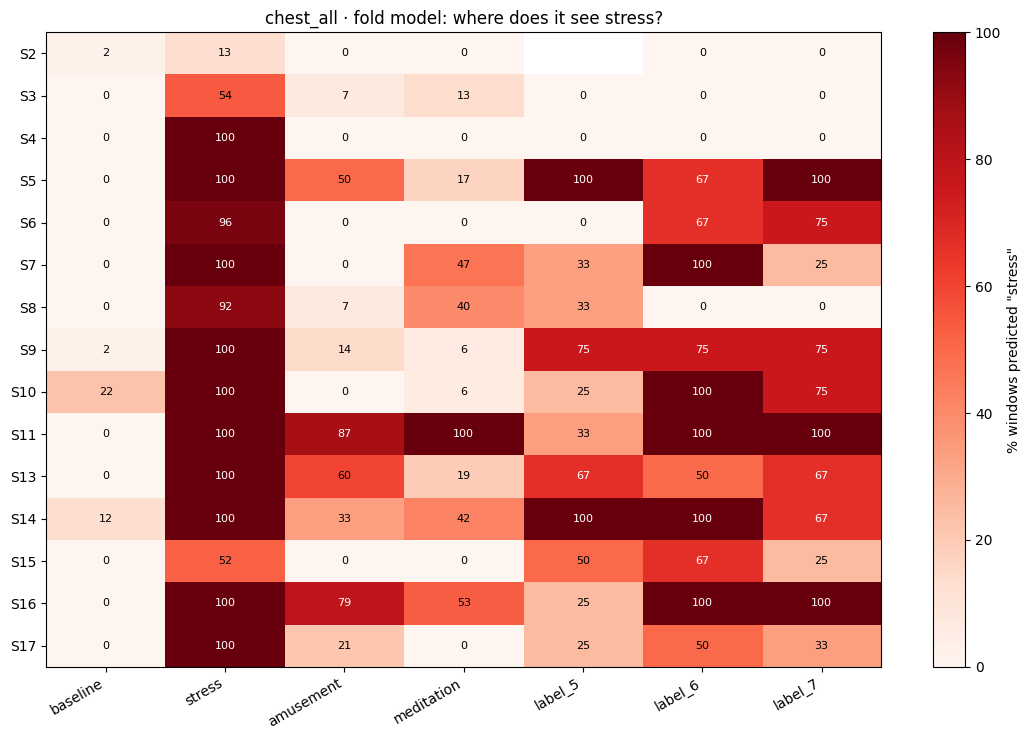

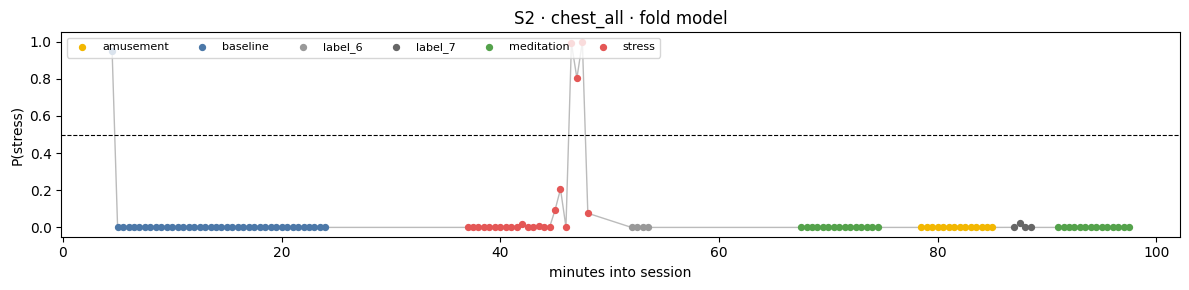

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  WESAD CNN-LSTM · Predict stress on EVERY window (all labels)
#  Paste into ONE Colab cell (CPU runtime is enough) and run.
#
#  For each subject it runs:
#    A) FOLD model  fold_<S>.weights.h5  → the subject was NOT in training
#                                          (honest, unseen-subject result)
#    B) FINAL model final_model.keras    → trained on baseline+stress of ALL
#                                          subjects (amusement/meditation are
#                                          still unseen windows for it)
#
#  Preprocessing is copied 1:1 from your training notebook:
#    merge bundles → feature order → median-impute → StandardScaler → to_3d
#  Fold scaler = refit on the other 14 subjects' baseline+stress windows,
#  exactly like run_loso() did.
# ═══════════════════════════════════════════════════════════════════════════

# ── CONFIG ─────────────────────────────────────────────────────────────────
BASE_PATH  = '/content/drive/MyDrive/Features'
MODEL_DIR  = '/content/drive/MyDrive/dl_models/cnn_lstm'
OUTPUT_DIR = '/content/drive/MyDrive/dl_results/all_label_predictions'

# Which trained experiment(s) to evaluate:
#   'all'                      → all 12 (still only a few minutes on CPU)
#   ['chest_all']              → just one
#   ['chest_all', 'wrist_all'] → any subset
RUN_EXPERIMENTS = 'all'

THRESHOLD = 0.5
MOUNT_DRIVE = True
# ───────────────────────────────────────────────────────────────────────────

EXPERIMENTS = {
    'chest_acc':         {'chest': ['acc']},
    'chest_eda':         {'chest': ['eda']},
    'chest_emg':         {'chest': ['emg']},
    'chest_heart':       {'chest': ['heart']},
    'chest_statistical': {'chest': ['statistical']},
    'wrist_acc':         {'wrist': ['acc']},
    'wrist_eda':         {'wrist': ['eda']},
    'wrist_heart':       {'wrist': ['heart']},
    'wrist_statistical': {'wrist': ['statistical']},
    'chest_all':  {'chest': ['acc', 'eda', 'emg', 'heart', 'statistical']},
    'wrist_all':  {'wrist': ['acc', 'eda', 'heart', 'statistical']},
    'multimodal': {'chest': ['acc', 'eda', 'emg', 'heart', 'statistical'],
                   'wrist': ['acc', 'eda', 'heart', 'statistical']},
}

LABEL_NAMES = {0: 'transient', 1: 'baseline', 2: 'stress', 3: 'amusement',
               4: 'meditation', 5: 'label_5', 6: 'label_6', 7: 'label_7'}

if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')

import json, gc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, balanced_accuracy_score)
warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

MERGE_KEYS       = ['subject', 'window_idx', 'start_time', 'end_time', 'label']
NON_FEATURE_COLS = set(MERGE_KEYS)
SENSOR_PREFIXES  = ['acc', 'eda', 'emg', 'heart', 'temp', 'bvp', 'resp', 'scl', 'scr']
OUT = Path(OUTPUT_DIR); OUT.mkdir(parents=True, exist_ok=True)


# ── Same functions as the training notebook ────────────────────────────────
def load_all_labels(config):
    """load_dataset() from training, but WITHOUT the baseline/stress filter."""
    all_dfs = []
    for modality, bundles in config.items():
        dfs = [pd.read_parquet(Path(BASE_PATH) / modality / f'all_{modality}_{b}.parquet')
               for b in bundles]
        merged = dfs[0]
        for df in dfs[1:]:
            merged = merged.merge(df, on=MERGE_KEYS)
        all_dfs.append(merged)
    final = all_dfs[0]
    for df in all_dfs[1:]:
        final = final.merge(df, on=MERGE_KEYS)
    return final.reset_index(drop=True)          # raw labels 1..7 kept


def get_feature_names(df):
    return [c for c in df.columns if c not in NON_FEATURE_COLS]


def group_by_sensor(feature_names):
    groups = {}
    for col in feature_names:
        matched = next((p for p in SENSOR_PREFIXES if col.lower().startswith(p)), None)
        groups.setdefault(matched if matched else 'other', []).append(col)
    return groups


def to_3d(X_2d, feature_names):
    groups  = group_by_sensor(feature_names)
    g_names = list(groups.keys())
    T       = max(len(v) for v in groups.values())
    c_idx   = {n: i for i, n in enumerate(feature_names)}
    X_3d    = np.zeros((X_2d.shape[0], len(g_names), T), dtype=np.float32)
    for gi, gn in enumerate(g_names):
        for fi, col in enumerate(groups[gn]):
            X_3d[:, gi, fi] = X_2d[:, c_idx[col]]
    return X_3d


def build_model(input_shape):
    inp = keras.Input(shape=input_shape)
    x = layers.Conv1D(64, 3, padding='same', activation='relu')(inp)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.2)(x)
    x = layers.Conv1D(128, 3, padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x); x = layers.Dropout(0.2)(x)
    x = layers.LSTM(64, return_sequences=False)(x); x = layers.Dropout(0.4)(x)
    x = layers.Dense(64, activation='relu')(x);     x = layers.Dropout(0.3)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    return keras.Model(inp, out)


def impute_scale(X_fit_raw, X_apply_raw, medians=None, scaler=None):
    """Fit (or reuse) medians + scaler on X_fit_raw, apply to X_apply_raw."""
    X_fit, X_app = X_fit_raw.copy(), X_apply_raw.copy()
    if medians is None:
        medians = np.nanmedian(X_fit, axis=0)
    for arr in (X_fit, X_app):
        m = np.isnan(arr)
        if m.any():
            arr[m] = np.take(medians, np.where(m)[1])
    if scaler is None:
        scaler = StandardScaler().fit(X_fit)
    X_sc = np.nan_to_num(scaler.transform(X_app), nan=0.0, posinf=0.0, neginf=0.0)
    return X_sc


def predict(model, X3d):
    return model(X3d, training=False).numpy().ravel()


# ── Metrics ────────────────────────────────────────────────────────────────
def binary_metrics(y_true, probs, thr=THRESHOLD):
    if len(y_true) == 0:
        return {}
    pred = (probs >= thr).astype(int)
    try:
        auc = roc_auc_score(y_true, probs)
    except ValueError:
        auc = np.nan
    tn = int(((pred == 0) & (y_true == 0)).sum()); fp = int(((pred == 1) & (y_true == 0)).sum())
    fn = int(((pred == 0) & (y_true == 1)).sum()); tp = int(((pred == 1) & (y_true == 1)).sum())
    return dict(n=len(y_true), accuracy=accuracy_score(y_true, pred),
                balanced_acc=balanced_accuracy_score(y_true, pred),
                precision=precision_score(y_true, pred, zero_division=0),
                recall=recall_score(y_true, pred, zero_division=0),
                specificity=tn / (tn + fp) if (tn + fp) else np.nan,
                f1=f1_score(y_true, pred, zero_division=0),
                roc_auc=auc, tp=tp, fp=fp, fn=fn, tn=tn)


def summarise(pred_df, tag):
    """Per subject: (1) original task  baseline vs stress,
                    (2) strict task    stress vs EVERYTHING else,
                    (3) % of windows flagged as stress for each real label."""
    rows = []
    for sub, g in pred_df.groupby('subject'):
        bs = g[g['label'].isin([1, 2])]
        orig   = binary_metrics((bs['label'] == 2).astype(int).values, bs['prob'].values)
        strict = binary_metrics((g['label'] == 2).astype(int).values, g['prob'].values)
        row = {'subject': sub}
        row.update({f'orig_{k}': v for k, v in orig.items()})
        row.update({f'strict_{k}': v for k, v in strict.items()})
        rows.append(row)
    metrics = pd.DataFrame(rows)
    metrics['subj_num'] = metrics['subject'].str[1:].astype(int)
    metrics = metrics.sort_values('subj_num').drop(columns='subj_num')

    flag = (pred_df.assign(flagged=pred_df['pred'])
            .pivot_table(index='subject', columns='label_name', values='flagged', aggfunc='mean'))
    cnt  = pred_df.pivot_table(index='subject', columns='label_name', values='pred', aggfunc='size')
    order = [LABEL_NAMES[k] for k in sorted(LABEL_NAMES) if LABEL_NAMES[k] in flag.columns]
    key = lambda idx: idx.str[1:].astype(int)
    flag = (flag[order] * 100).round(1).sort_index(key=key)
    cnt  = cnt[order].sort_index(key=key)

    # pooled over all subjects
    pooled = (pred_df.groupby('label_name')['pred']
              .agg(windows='size', flagged_stress='sum', pct_flagged='mean'))
    pooled['pct_flagged'] = (pooled['pct_flagged'] * 100).round(1)
    pooled = pooled.reindex([o for o in order if o in pooled.index])

    print(f"\n{'─'*70}\n {tag}\n{'─'*70}")
    print("\n% of windows the model called STRESS, by REAL label (rows = subjects):")
    print(flag.fillna('-').to_string())
    print("\nPooled over all subjects:")
    print(pooled.to_string())
    cols = ['subject', 'orig_accuracy', 'orig_f1', 'orig_roc_auc',
            'strict_accuracy', 'strict_balanced_acc', 'strict_precision',
            'strict_recall', 'strict_f1']
    print("\nPer-subject metrics  (orig = baseline vs stress | strict = stress vs all other labels):")
    print(metrics[cols].round(3).to_string(index=False))
    print("\nMean across subjects:")
    print(metrics[cols[1:]].mean().round(3).to_string())
    return metrics, flag, cnt, pooled


# ── Main loop ──────────────────────────────────────────────────────────────
if RUN_EXPERIMENTS == 'all':
    RUN_EXPERIMENTS = list(EXPERIMENTS)
elif isinstance(RUN_EXPERIMENTS, str):
    RUN_EXPERIMENTS = [RUN_EXPERIMENTS]      # e.g. 'chest_all' without brackets
unknown = [e for e in RUN_EXPERIMENTS if e not in EXPERIMENTS]
if unknown:
    raise ValueError(f"Unknown experiment(s) {unknown}. Choose from {list(EXPERIMENTS)}")

for exp in RUN_EXPERIMENTS:
    config  = EXPERIMENTS[exp]
    exp_dir = Path(MODEL_DIR) / exp
    print(f"\n{'═'*70}\n  EXPERIMENT: {exp}\n{'═'*70}")

    df   = load_all_labels(config)
    feat = get_feature_names(df)
    X_all_raw = df[feat].values.astype(np.float32)
    is_bs     = df['label'].isin([1, 2]).values          # training-eligible rows
    df['label_name'] = df['label'].map(LABEL_NAMES).fillna(df['label'].astype(str))
    subjects = sorted(df['subject'].unique(), key=lambda s: int(s[1:]))
    print(f"windows={len(df)} | features={len(feat)} | subjects={len(subjects)}")
    print("label counts:", df['label_name'].value_counts().to_dict())

    input_shape = to_3d(X_all_raw[:1], feat).shape[1:]
    print("model input shape:", input_shape)

    # ── A) fold models (unseen subject) ────────────────────────────────────
    fold_rows = []
    tf.keras.backend.clear_session()
    model = build_model(input_shape)
    for sub in subjects:
        wpath = exp_dir / f'fold_{sub}.weights.h5'
        if not wpath.exists():
            print(f"  [skip] {wpath.name} not found"); continue
        model.load_weights(str(wpath))
        train_mask = is_bs & (df['subject'] != sub).values  # same as run_loso
        test_mask  = (df['subject'] == sub).values           # ALL labels
        X_te = impute_scale(X_all_raw[train_mask], X_all_raw[test_mask])
        probs = predict(model, to_3d(X_te, feat))
        part = df.loc[test_mask, ['subject', 'window_idx', 'start_time', 'end_time',
                                  'label', 'label_name']].copy()
        part['prob'] = probs
        part['pred'] = (probs >= THRESHOLD).astype(int)
        fold_rows.append(part)
        print(f"  fold {sub:>4}: {test_mask.sum()} windows predicted")
    del model; gc.collect()

    if fold_rows:
        fold_pred = pd.concat(fold_rows, ignore_index=True)
        fold_pred.insert(0, 'model', 'fold')
        m, f, c, p = summarise(fold_pred, f"{exp} · FOLD models (subject unseen)")
        fold_pred.to_csv(OUT / f'{exp}_fold_predictions.csv', index=False)
        m.to_csv(OUT / f'{exp}_fold_metrics.csv', index=False)
        f.to_csv(OUT / f'{exp}_fold_pct_flagged_by_label.csv')
        c.to_csv(OUT / f'{exp}_window_counts_by_label.csv')

    # ── B) final model (trained on all subjects' baseline+stress) ─────────
    fpath = exp_dir / 'final_model.keras'
    if fpath.exists():
        tf.keras.backend.clear_session()
        final = keras.models.load_model(str(fpath), compile=False)
        meta_p, sc_p, md_p = exp_dir / 'meta.json', exp_dir / 'scaler.joblib', exp_dir / 'medians.npy'
        feat_final = json.load(open(meta_p))['feature_names'] if meta_p.exists() else feat
        X_final_raw = df[feat_final].values.astype(np.float32)
        if sc_p.exists() and md_p.exists():
            import joblib
            scaler, medians = joblib.load(sc_p), np.load(md_p)
            X_sc = impute_scale(X_final_raw[is_bs], X_final_raw, medians=medians, scaler=scaler)
            print("\nfinal model: using saved scaler.joblib + medians.npy")
        else:
            X_sc = impute_scale(X_final_raw[is_bs], X_final_raw)
            print("\nfinal model: scaler refit on all baseline+stress windows (no saved scaler found)")
        probs = predict(final, to_3d(X_sc, feat_final))
        final_pred = df[['subject', 'window_idx', 'start_time', 'end_time',
                         'label', 'label_name']].copy()
        final_pred['prob'] = probs
        final_pred['pred'] = (probs >= THRESHOLD).astype(int)
        final_pred.insert(0, 'model', 'final')
        m, f, c, p = summarise(final_pred,
                               f"{exp} · FINAL model (baseline/stress windows were in training!)")
        final_pred.to_csv(OUT / f'{exp}_final_predictions.csv', index=False)
        m.to_csv(OUT / f'{exp}_final_metrics.csv', index=False)
        f.to_csv(OUT / f'{exp}_final_pct_flagged_by_label.csv')
        del final; gc.collect()
    else:
        print(f"  [skip] {fpath} not found")

print(f"\n✅ Done. CSVs saved in {OUT}")


# ── Optional plots (run after the loop) ────────────────────────────────────
import matplotlib.pyplot as plt

def plot_heatmap(exp='chest_all', which='fold'):
    """Subjects × real label, colour = % of windows called stress."""
    tbl = pd.read_csv(OUT / f'{exp}_{which}_pct_flagged_by_label.csv', index_col=0)
    fig, ax = plt.subplots(figsize=(1.3 * tbl.shape[1] + 2, 0.4 * tbl.shape[0] + 1.5))
    im = ax.imshow(tbl.values, cmap='Reds', vmin=0, vmax=100, aspect='auto')
    ax.set_xticks(range(tbl.shape[1])); ax.set_xticklabels(tbl.columns, rotation=30, ha='right')
    ax.set_yticks(range(tbl.shape[0])); ax.set_yticklabels(tbl.index)
    for i in range(tbl.shape[0]):
        for j in range(tbl.shape[1]):
            v = tbl.values[i, j]
            if not np.isnan(v):
                ax.text(j, i, f'{v:.0f}', ha='center', va='center',
                        color='white' if v > 60 else 'black', fontsize=8)
    plt.colorbar(im, ax=ax, label='% windows predicted "stress"')
    ax.set_title(f'{exp} · {which} model: where does it see stress?')
    plt.tight_layout(); plt.savefig(OUT / f'{exp}_{which}_heatmap.png', dpi=150); plt.show()


def plot_timeline(subject='S2', exp='chest_all', which='fold'):
    """Stress probability over the session, coloured by the real label."""
    d = pd.read_csv(OUT / f'{exp}_{which}_predictions.csv')
    d = d[d['subject'] == subject].sort_values('start_time')
    colours = {'baseline': '#4C78A8', 'stress': '#E45756', 'amusement': '#F2B701',
               'meditation': '#54A24B', 'label_6': '#999999', 'label_7': '#666666'}
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(d['start_time'] / 60, d['prob'], color='#bbbbbb', lw=1, zorder=1)
    for name, g in d.groupby('label_name'):
        ax.scatter(g['start_time'] / 60, g['prob'], s=18, label=name,
                   color=colours.get(name, '#000000'), zorder=2)
    ax.axhline(THRESHOLD, ls='--', color='black', lw=0.8)
    ax.set_ylim(-0.05, 1.05); ax.set_xlabel('minutes into session'); ax.set_ylabel('P(stress)')
    ax.set_title(f'{subject} · {exp} · {which} model'); ax.legend(ncol=6, fontsize=8, loc='upper left')
    plt.tight_layout(); plt.savefig(OUT / f'{exp}_{which}_{subject}_timeline.png', dpi=150); plt.show()


plot_heatmap('chest_all', 'fold')
plot_timeline('S2', 'chest_all', 'fold')

Loaded 21648 fold rows · experiments: ['chest_acc', 'chest_all', 'chest_eda', 'chest_emg', 'chest_heart', 'chest_statistical', 'multimodal', 'wrist_acc', 'wrist_all', 'wrist_eda', 'wrist_heart', 'wrist_statistical']


██████████████████████████████████████████████████████████████████████████
 STEP 1 · Sanity check — does it reproduce training?
██████████████████████████████████████████████████████████████████████████
What to look for: orig_* numbers per subject must equal the per-fold lines in your training log (e.g. chest_all S2: Acc=0.6667, TP=3, FP=1, FN=20, TN=39). If they differ, the preprocessing or weights don't match and nothing below can be trusted. 

[chest_all]
subject  orig_accuracy  orig_tp  orig_fp  orig_fn  orig_tn
     S2         0.6667        3        1       20       39
     S3         0.8281       13        0       11       40
     S4         1.0000       23        0        0       40
     S5         1.0000       23        0        0       41
     S6         0.9846  

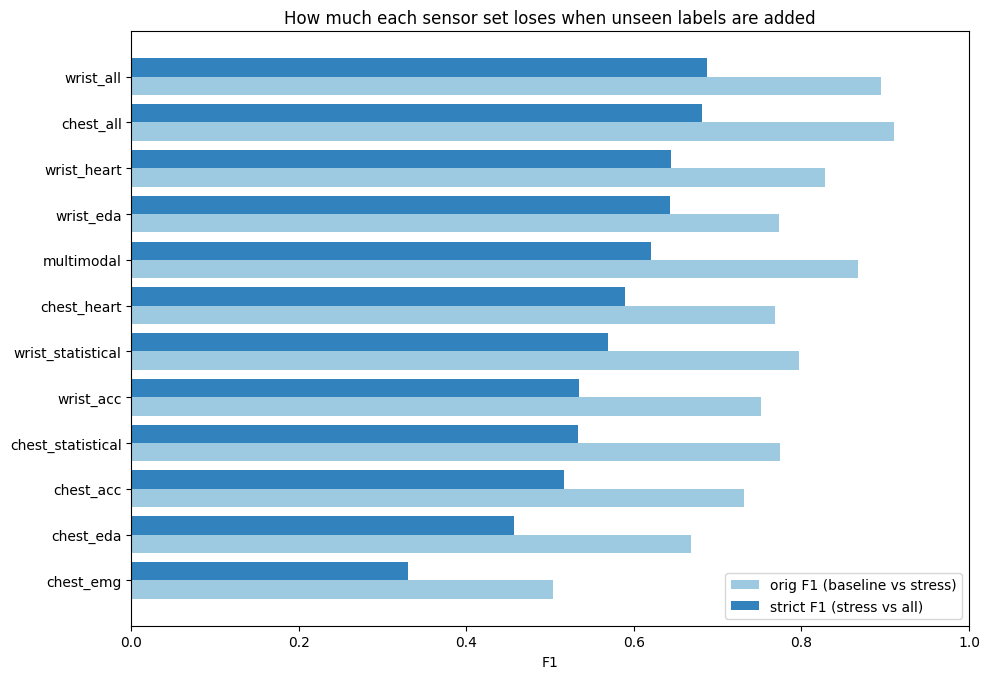



██████████████████████████████████████████████████████████████████████████
 STEP 3 · Source of false alarms
██████████████████████████████████████████████████████████████████████████
What to look for: Of all windows wrongly called stress, what share is baseline vs amusement vs meditation? If amusement dominates, the model learned 'arousal' rather than 'stress' — a key finding to report. Compare chest vs wrist rows. 

label_name         total_false_alarms  baseline  amusement  meditation  label_6  label_7
experiment                                                                              
chest_acc                         383      26.4       26.4        32.9      8.1      6.3
chest_all                         229       7.0       22.7        45.4     13.1     11.8
chest_eda                         574      36.2       16.6        35.0      7.1      5.1
chest_emg                         749      41.4       16.3        35.2      3.3      3.7
chest_heart                       294      

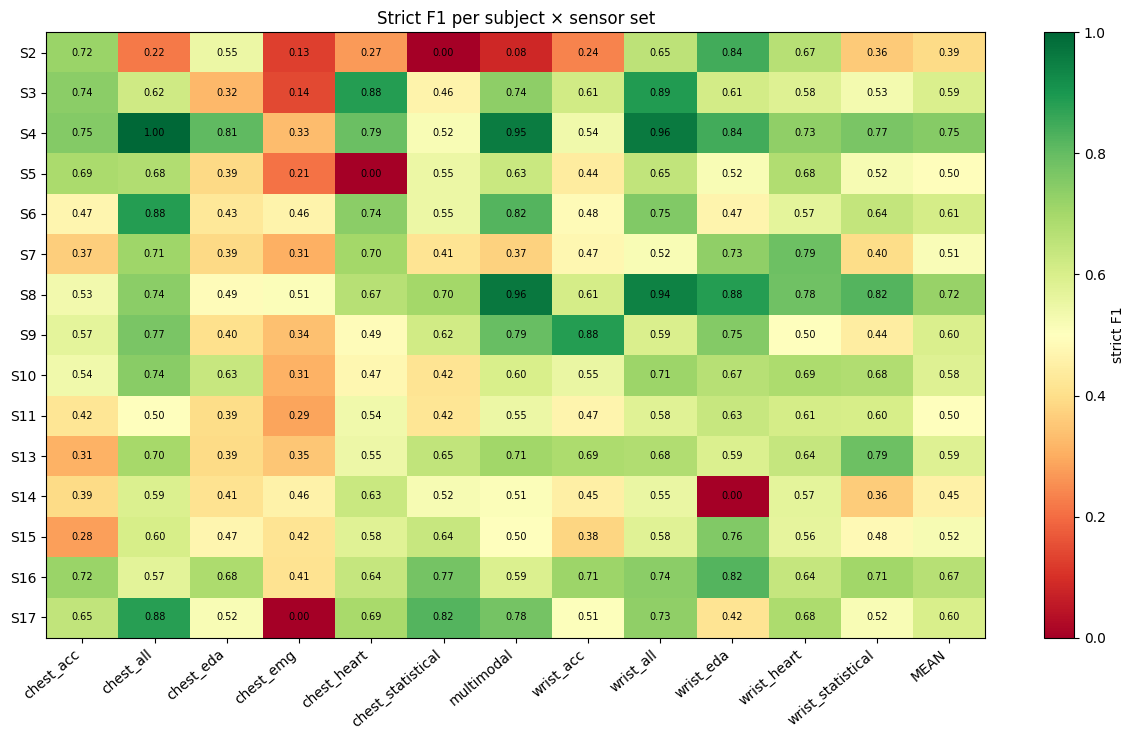



██████████████████████████████████████████████████████████████████████████
 STEP 5 · How confident is the model per label? (chest_all)
██████████████████████████████████████████████████████████████████████████
What to look for: Box plot: if amusement probabilities sit just above 0.5 the confusion is mild and a higher threshold helps; if they sit near 1.0 the model truly can't tell. Threshold table: % flagged per label as the cut-off moves. CAUTION: picking the best threshold here uses test data — report it as exploratory only. 



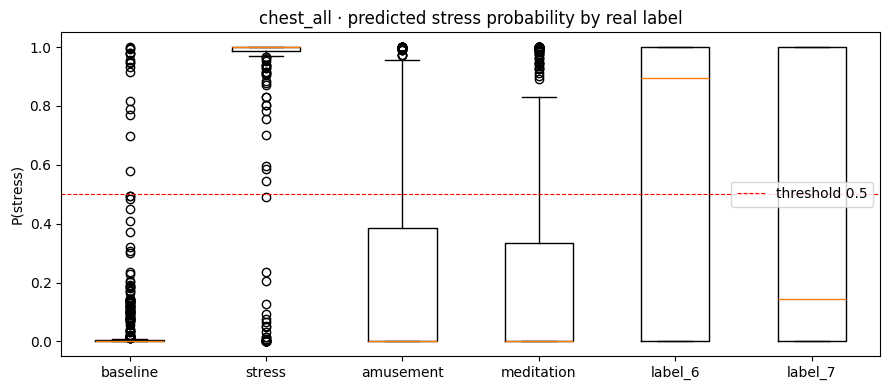

 threshold  strict_f1  strict_bal_acc  %baseline  %stress  %amusement  %meditation  %label_6  %label_7
       0.1      0.612           0.816     10.604   88.398      31.308       30.396    62.264    52.632
       0.2      0.648           0.835      4.731   88.122      29.907       27.533    60.377    49.123
       0.3      0.660           0.840      3.915   87.569      26.636       25.991    58.491    49.123
       0.4      0.672           0.846      3.426   87.569      24.299       24.009    56.604    49.123
       0.5      0.681           0.850      2.610   87.293      24.299       22.907    56.604    47.368
       0.6      0.691           0.852      2.447   86.464      21.028       20.925    56.604    45.614
       0.7      0.703           0.857      2.284   86.464      19.159       19.383    56.604    42.105
       0.8      0.713           0.860      1.958   85.635      16.822       17.401    56.604    40.351
       0.9      0.715           0.855      1.794   83.702      14.953    

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
#  Step-by-step analysis of predict_all_labels.py outputs
#  Run in Colab AFTER predict_all_labels.py. Each step prints a table,
#  saves a PNG/CSV into OUT/analysis, and says what to look for.
# ═══════════════════════════════════════════════════════════════════════════
OUTPUT_DIR = '/content/drive/MyDrive/dl_results/all_label_predictions'
FOCUS_EXP  = 'chest_all'     # experiment used for the deep-dive steps (4–7)
THRESHOLD  = 0.5

import glob, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, f1_score, balanced_accuracy_score
warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)

OUT = Path(OUTPUT_DIR); AN = OUT / 'analysis'; AN.mkdir(exist_ok=True)
NON_STRESS = ['baseline', 'amusement', 'meditation', 'label_6', 'label_7']
LABEL_ORDER = ['baseline', 'stress', 'amusement', 'meditation', 'label_6', 'label_7']
subj_key = lambda s: s.str[1:].astype(int)


def load(which):
    """All <exp>_<which>_predictions.csv files stacked, with an 'experiment' column."""
    frames = []
    for f in sorted(glob.glob(str(OUT / f'*_{which}_predictions.csv'))):
        exp = Path(f).name.replace(f'_{which}_predictions.csv', '')
        frames.append(pd.read_csv(f).assign(experiment=exp))
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


def header(n, title, look_for):
    print(f"\n\n{'█'*74}\n STEP {n} · {title}\n{'█'*74}")
    print("What to look for:", look_for, "\n")


fold  = load('fold')
final = load('final')
assert len(fold), f"No *_fold_predictions.csv in {OUT} — run predict_all_labels.py first"
fold['is_stress'] = (fold['label_name'] == 'stress').astype(int)
EXPS = sorted(fold['experiment'].unique())
print(f"Loaded {len(fold)} fold rows · experiments: {EXPS}")


# ── STEP 1 · Sanity check ──────────────────────────────────────────────────
header(1, "Sanity check — does it reproduce training?",
       "orig_* numbers per subject must equal the per-fold lines in your training log "
       "(e.g. chest_all S2: Acc=0.6667, TP=3, FP=1, FN=20, TN=39). If they differ, the "
       "preprocessing or weights don't match and nothing below can be trusted.")
m = pd.read_csv(OUT / f'{FOCUS_EXP}_fold_metrics.csv')
print(f"[{FOCUS_EXP}]")
print(m[['subject', 'orig_accuracy', 'orig_tp', 'orig_fp', 'orig_fn', 'orig_tn']]
      .round(4).to_string(index=False))


# ── STEP 2 · Leaderboard: which sensor set copes best with unseen labels ──
header(2, "Leaderboard across experiments (fold models, all subjects pooled)",
       "Compare orig_f1 (training task) with strict_f1 / strict_bal_acc (real-world-like task). "
       "A big drop means that sensor set fires on non-stress states. The '% flagged' columns "
       "show WHICH states cause it. Best model = high stress %, low everything else.")
rows = []
for exp, g in fold.groupby('experiment'):
    bs = g[g['label_name'].isin(['baseline', 'stress'])]
    r = dict(experiment=exp,
             orig_f1=f1_score(bs['is_stress'], bs['pred']),
             strict_f1=f1_score(g['is_stress'], g['pred']),
             strict_bal_acc=balanced_accuracy_score(g['is_stress'], g['pred']),
             strict_auc=roc_auc_score(g['is_stress'], g['prob']))
    for lab in LABEL_ORDER:
        sel = g[g['label_name'] == lab]
        if len(sel):
            r[f'%{lab}'] = 100 * sel['pred'].mean()
    rows.append(r)
board = pd.DataFrame(rows).sort_values('strict_f1', ascending=False)
board['f1_drop'] = board['orig_f1'] - board['strict_f1']
print(board.round(3).to_string(index=False))
board.to_csv(AN / 'step2_leaderboard.csv', index=False)

fig, ax = plt.subplots(figsize=(10, 0.45 * len(board) + 1.5))
y = np.arange(len(board))
ax.barh(y + 0.2, board['orig_f1'], 0.4, label='orig F1 (baseline vs stress)', color='#9ecae1')
ax.barh(y - 0.2, board['strict_f1'], 0.4, label='strict F1 (stress vs all)', color='#3182bd')
ax.set_yticks(y); ax.set_yticklabels(board['experiment']); ax.invert_yaxis()
ax.set_xlim(0, 1); ax.set_xlabel('F1'); ax.legend(loc='lower right')
ax.set_title('How much each sensor set loses when unseen labels are added')
plt.tight_layout(); plt.savefig(AN / 'step2_leaderboard.png', dpi=150); plt.show()


# ── STEP 3 · Where do false alarms come from? ─────────────────────────────
header(3, "Source of false alarms",
       "Of all windows wrongly called stress, what share is baseline vs amusement vs "
       "meditation? If amusement dominates, the model learned 'arousal' rather than "
       "'stress' — a key finding to report. Compare chest vs wrist rows.")
fp = fold[(fold['pred'] == 1) & (fold['is_stress'] == 0)]
src = (fp.groupby(['experiment', 'label_name']).size().unstack(fill_value=0)
       .reindex(columns=[c for c in NON_STRESS if c in fp['label_name'].unique()]))
src_pct = (src.div(src.sum(axis=1), axis=0) * 100).round(1)
src_pct.insert(0, 'total_false_alarms', src.sum(axis=1))
print(src_pct.to_string())
src_pct.to_csv(AN / 'step3_false_alarm_sources.csv')


# ── STEP 4 · Which subjects are hard? ─────────────────────────────────────
header(4, "Per-subject difficulty (strict F1, fold models)",
       "Rows that are low in EVERY column = that person's physiology is unusual "
       "(a subject problem, not a sensor problem). A subject low only for some sensors "
       "points to bad signal quality on that sensor for that person.")
sub_tbl = (fold.groupby(['subject', 'experiment'])
           .apply(lambda g: f1_score(g['is_stress'], g['pred'], zero_division=0))
           .unstack().sort_index(key=subj_key))
sub_tbl['MEAN'] = sub_tbl.mean(axis=1)
print(sub_tbl.round(2).to_string())
sub_tbl.to_csv(AN / 'step4_subject_difficulty.csv')

fig, ax = plt.subplots(figsize=(0.8 * sub_tbl.shape[1] + 2, 0.4 * len(sub_tbl) + 1.5))
im = ax.imshow(sub_tbl.values, cmap='RdYlGn', vmin=0, vmax=1, aspect='auto')
ax.set_xticks(range(sub_tbl.shape[1])); ax.set_xticklabels(sub_tbl.columns, rotation=40, ha='right')
ax.set_yticks(range(len(sub_tbl))); ax.set_yticklabels(sub_tbl.index)
for i in range(sub_tbl.shape[0]):
    for j in range(sub_tbl.shape[1]):
        ax.text(j, i, f'{sub_tbl.values[i, j]:.2f}', ha='center', va='center', fontsize=7)
plt.colorbar(im, ax=ax, label='strict F1'); ax.set_title('Strict F1 per subject × sensor set')
plt.tight_layout(); plt.savefig(AN / 'step4_subject_difficulty.png', dpi=150); plt.show()


# ── STEP 5 · Probability distributions + threshold sweep ──────────────────
g = fold[fold['experiment'] == FOCUS_EXP]
header(5, f"How confident is the model per label? ({FOCUS_EXP})",
       "Box plot: if amusement probabilities sit just above 0.5 the confusion is mild "
       "and a higher threshold helps; if they sit near 1.0 the model truly can't tell. "
       "Threshold table: % flagged per label as the cut-off moves. CAUTION: picking the "
       "best threshold here uses test data — report it as exploratory only.")
labs = [l for l in LABEL_ORDER if l in g['label_name'].unique()]
fig, ax = plt.subplots(figsize=(9, 4))
ax.boxplot([g.loc[g['label_name'] == l, 'prob'] for l in labs], showfliers=True)
ax.set_xticks(range(1, len(labs) + 1)); ax.set_xticklabels(labs)   # works on old + new matplotlib
ax.axhline(THRESHOLD, ls='--', color='red', lw=0.8, label=f'threshold {THRESHOLD}')
ax.set_ylabel('P(stress)'); ax.set_title(f'{FOCUS_EXP} · predicted stress probability by real label')
ax.legend(); plt.tight_layout(); plt.savefig(AN / 'step5_prob_by_label.png', dpi=150); plt.show()

sweep = []
for t in np.round(np.arange(0.1, 0.95, 0.1), 1):
    p = (g['prob'] >= t).astype(int)
    r = {'threshold': t,
         'strict_f1': f1_score(g['is_stress'], p, zero_division=0),
         'strict_bal_acc': balanced_accuracy_score(g['is_stress'], p)}
    for l in labs:
        r[f'%{l}'] = 100 * p[g['label_name'] == l].mean()
    sweep.append(r)
sweep = pd.DataFrame(sweep)
print(sweep.round(3).to_string(index=False))
sweep.to_csv(AN / f'step5_threshold_sweep_{FOCUS_EXP}.csv', index=False)


# ── STEP 6 · Fold vs final model ──────────────────────────────────────────
header(6, "Generalisation gap: fold (unseen subject) vs final (seen subject)",
       "orig_f1 gap = how much the final model benefits from having seen the person "
       "(inflated, don't report final as accuracy). The %amusement / %meditation columns "
       "are fair for BOTH models (those windows were never trained on) — if final is much "
       "better there, more training subjects would likely help.")
if len(final):
    final['is_stress'] = (final['label_name'] == 'stress').astype(int)
    gap = []
    for exp in EXPS:
        r = {'experiment': exp}
        for name, d in [('fold', fold), ('final', final)]:
            e = d[d['experiment'] == exp]
            if not len(e):
                continue
            bs = e[e['label_name'].isin(['baseline', 'stress'])]
            r[f'{name}_orig_f1'] = f1_score(bs['is_stress'], bs['pred'])
            for l in ['amusement', 'meditation']:
                r[f'{name}_%{l}'] = 100 * e.loc[e['label_name'] == l, 'pred'].mean()
        gap.append(r)
    gap = pd.DataFrame(gap)
    print(gap.round(3).to_string(index=False))
    gap.to_csv(AN / 'step6_fold_vs_final.csv', index=False)
else:
    print("No *_final_predictions.csv found — skipped.")


# ── STEP 7 · Time effects: does stress 'linger'? ──────────────────────────
header(7, f"Carry-over after stress ({FOCUS_EXP})",
       "Physiology (EDA, heart rate) recovers slowly. If non-stress windows shortly after "
       "the stress block are flagged far more than later ones, many 'false alarms' are "
       "really lingering arousal — not a model bug. Also check the first vs last stress "
       "windows: low detection at the start = the body hadn't reacted yet.")
d = g.sort_values(['subject', 'start_time']).copy()
carry = []
for sub, s in d.groupby('subject'):
    stress_end = s.loc[s['label_name'] == 'stress', 'end_time']
    if stress_end.empty:
        continue
    last_end = stress_end.max()
    after = s[(s['label_name'] != 'stress') & (s['start_time'] >= last_end - 30)].copy()
    after['min_after_stress'] = (after['start_time'] - last_end) / 60
    carry.append(after)
    stress_idx = s.index[s['label_name'] == 'stress']
    pos = np.arange(len(stress_idx)) / max(len(stress_idx) - 1, 1)   # 0 = first, 1 = last
    d.loc[stress_idx, 'stress_part'] = pd.cut(pos, [-0.01, 1/3, 2/3, 1.01],
                                              labels=['first third', 'middle', 'last third']).astype(str)
if carry:
    carry = pd.concat(carry)
    carry['bucket'] = pd.cut(carry['min_after_stress'], [-1, 5, 10, 20, 1e9],
                             labels=['0–5 min', '5–10 min', '10–20 min', '>20 min'])
    tbl = carry.groupby('bucket')['pred'].agg(windows='size', pct_flagged='mean')
    tbl['pct_flagged'] = (tbl['pct_flagged'] * 100).round(1)
    print("Non-stress windows AFTER the stress block, by time since it ended:")
    print(tbl.to_string())
    tbl.to_csv(AN / f'step7_carryover_{FOCUS_EXP}.csv')
part = (d.dropna(subset=['stress_part']).groupby('stress_part')['pred'].mean() * 100
        ).reindex(['first third', 'middle', 'last third'])
print("\nDetection rate inside the stress block:")
print(part.round(1).to_string())


# ── Summary ───────────────────────────────────────────────────────────────
print(f"\n\n{'═'*74}\n SUMMARY\n{'═'*74}")
best = board.iloc[0]
print(f"• Best sensor set on the strict task: {best['experiment']} "
      f"(strict F1 {best['strict_f1']:.3f}, orig F1 {best['orig_f1']:.3f})")
worst_drop = board.sort_values('f1_drop', ascending=False).iloc[0]
print(f"• Largest drop when unseen labels added: {worst_drop['experiment']} "
      f"(−{worst_drop['f1_drop']:.3f} F1)")
if 'amusement' in src_pct.columns:
    a = src_pct.loc[FOCUS_EXP, 'amusement'] if FOCUS_EXP in src_pct.index else np.nan
    print(f"• {FOCUS_EXP}: amusement causes {a:.1f}% of its false alarms")
hard = sub_tbl['MEAN'].sort_values().head(3)
print(f"• Hardest subjects overall: {', '.join(f'{s} ({v:.2f})' for s, v in hard.items())}")
print(f"\nAll tables/plots saved in {AN}")

In [ ]:
import pandas as pd
from sklearn.metrics import f1_score, balanced_accuracy_score
D = '/content/drive/MyDrive/dl_results/all_label_predictions/'
c = pd.read_csv(D + 'chest_all_fold_predictions.csv')
w = pd.read_csv(D + 'wrist_all_fold_predictions.csv')
k = ['subject', 'window_idx']
f = c.merge(w[k + ['prob']], on=k, suffixes=('_c', '_w'))
f['prob'] = (f.prob_c + f.prob_w) / 2                     # same fusion as the paper
f['pred'] = (f.prob >= 0.5).astype(int)
f['y'] = (f.label_name == 'stress').astype(int)

bs = f[f.label_name.isin(['baseline', 'stress'])]
print('PAPER TASK  pooled acc', round((bs.pred == bs.y).mean(), 4),
      '| F1', round(f1_score(bs.y, bs.pred), 4))          # should be ~0.9538 (Table III)
print('STRICT TASK F1', round(f1_score(f.y, f.pred), 3),
      '| balanced acc', round(balanced_accuracy_score(f.y, f.pred), 3))
print('\n% called stress, by real label:')
print((f.groupby('label_name').pred.mean() * 100).round(1))

PAPER TASK  pooled acc 0.9538 | F1 0.936
STRICT TASK F1 0.738 | balanced acc 0.885

% called stress, by real label:
label_name
amusement     22.9
baseline       2.0
label_5       33.3
label_6       49.1
label_7       36.8
meditation    16.7
stress        90.9
Name: pred, dtype: float64
